# Análise de Dados de Conversas do WhatsApp

**Trabalho de Data Science — A2**

Este notebook lê a exportação `.txt` de uma conversa em **grupo** do WhatsApp (Android ou iPhone, **sem mídia**), monta um DataFrame com as features **data**, **hora**, **remetente** e **mensagem**.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from whatsapp_analise import ler_conversa, listar_remetentes, resumo_conversas, historico_remetente
from whatsapp_analise.graficos import grafico_historico_remetente, grafico_linhas, grafico_pizza
from whatsapp_analise.interface import (
    criar_painel, criar_upload, descrever_leitura, mostrar_figura, tabela_rolavel,
)

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100

---

## 1. Carregar a conversa

Por padrão é lido um arquivo de conversas pessoal. Para analisar outra conversa, use o botão **Carregar .txt** (a tabela e o painel abaixo são atualizados) ou troque o `CAMINHO` e rode o notebook de novo (**Run All**).

In [2]:
CAMINHO = "dados/chat.txt"

resultado = ler_conversa(CAMINHO)
df = resultado.df
print(descrever_leitura(resultado))



def carregar(novo):
    """Chamada pelo upload: troca a conversa e atualiza a tabela e o painel."""
    global resultado, df
    resultado, df = novo, novo.df
    saida_tabela.update(tabela_rolavel(df))
    saida_painel.update(criar_painel(df))


display(criar_upload(carregar))

Formato detectado: iPhone (datas em mês/dia)
Mensagens: 996
Remetentes: 10
Período: 29/09/2025 a 19/09/2026
Mensagens do sistema ignoradas: 7


---

## 2. Tabela completa

In [3]:
saida_tabela = display(tabela_rolavel(df), display_id=True)

,data,hora,remetente,mensagem
0,2025-09-29,12:41:32,Henrique,<imagem ocultada> 😑
1,2025-09-29,12:41:40,Henrique,vcs viram essa porra
2,2025-09-29,12:42:19,Henrique,se essa parada for pra frente
3,2025-09-29,12:42:28,Henrique,Roblox pode fechar porta
4,2025-09-29,12:42:36,Henrique,assim como Habbo
5,2025-09-29,12:42:37,Henrique,...
6,2025-09-29,18:08:52,André Falavinha,Entrou um cara com o sotaque do cara do Rappa no ônibus
7,2025-09-29,18:10:49,+55 41 9925-8366,KKKKKK
8,2025-09-29,18:10:52,+55 41 9925-8366,Full aleatório
9,2025-09-29,18:11:07,+55 41 9925-8366,Mas n entendi o negócio do Roblox


## 3. Painel interativo

Escolha a análise, o remetente (quando se aplica) e clique em **Executar**. O painel precisa de um kernel em execução; as seções seguintes mostram as mesmas análises direto nas células.

In [4]:
saida_painel = display(criar_painel(df), display_id=True)

---

## 4. Resumo das conversas

Remetentes ordenados do que mais enviou mensagens para o que menos enviou.

In [5]:
resumo_conversas(df)

,remetente,total_mensagens,percentual
1,Henrique,434,43.6
2,+55 41 9944-1713,206,20.7
3,André Falavinha,110,11.0
4,+55 41 9947-7414,82,8.2
5,Lore,56,5.6
6,Você,44,4.4
7,+55 41 9925-8366,35,3.5
8,+55 41 9164-0065,18,1.8
9,Gabriel,10,1.0
10,+55 41 9694-7799,1,0.1


---

## 5. Histórico do remetente

Mensagens de um remetente, com data e hora. Troque `REMETENTE` por qualquer nome da lista.

In [6]:
print("Remetentes:", listar_remetentes(df))
REMETENTE = listar_remetentes(df)[0]
historico = historico_remetente(df, REMETENTE)
print(f"{REMETENTE}: {len(historico)} mensagens")
tabela_rolavel(historico)

Remetentes: ['Henrique', '+55 41 9944-1713', 'André Falavinha', '+55 41 9947-7414', 'Lore', 'Você', '+55 41 9925-8366', '+55 41 9164-0065', 'Gabriel', '+55 41 9694-7799']
Henrique: 434 mensagens


,data,hora,mensagem
0,2025-09-29,12:41:32,<imagem ocultada> 😑
1,2025-09-29,12:41:40,vcs viram essa porra
2,2025-09-29,12:42:19,se essa parada for pra frente
3,2025-09-29,12:42:28,Roblox pode fechar porta
4,2025-09-29,12:42:36,assim como Habbo
5,2025-09-29,12:42:37,...
6,2025-09-29,18:21:56,e vc nem pegou o número pra gente botar de vocal ?
7,2025-09-29,18:22:32,sem loot boxes o roblox morre
8,2025-09-29,18:24:28,https://open.spotify.com/album/1lrNGJv5aIKpx4bznJyHCF?si=-RsEg_OGReuzglD2kXR-gw
9,2025-09-29,18:24:36,muito bom o album


---

## 6. Gráfico do histórico do remetente

Quantidade de mensagens por dia, primeiro do remetente escolhido e depois de todos os remetentes, cada um no seu gráfico.

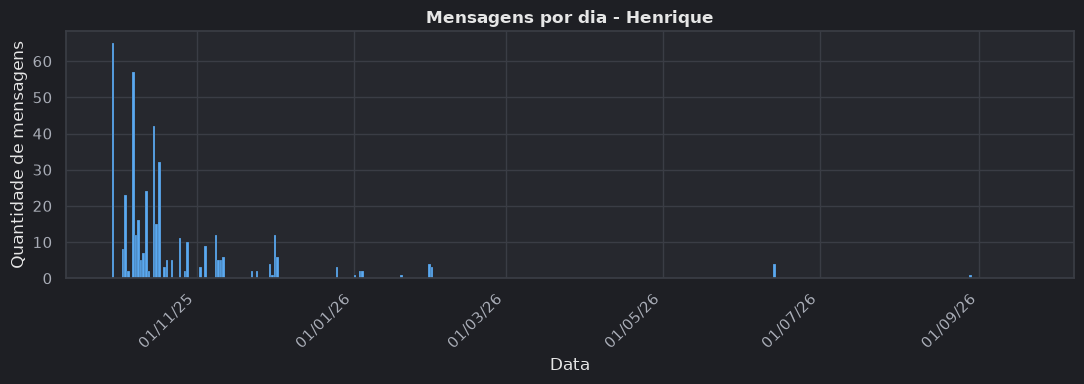

In [7]:
mostrar_figura(grafico_historico_remetente(df, REMETENTE))

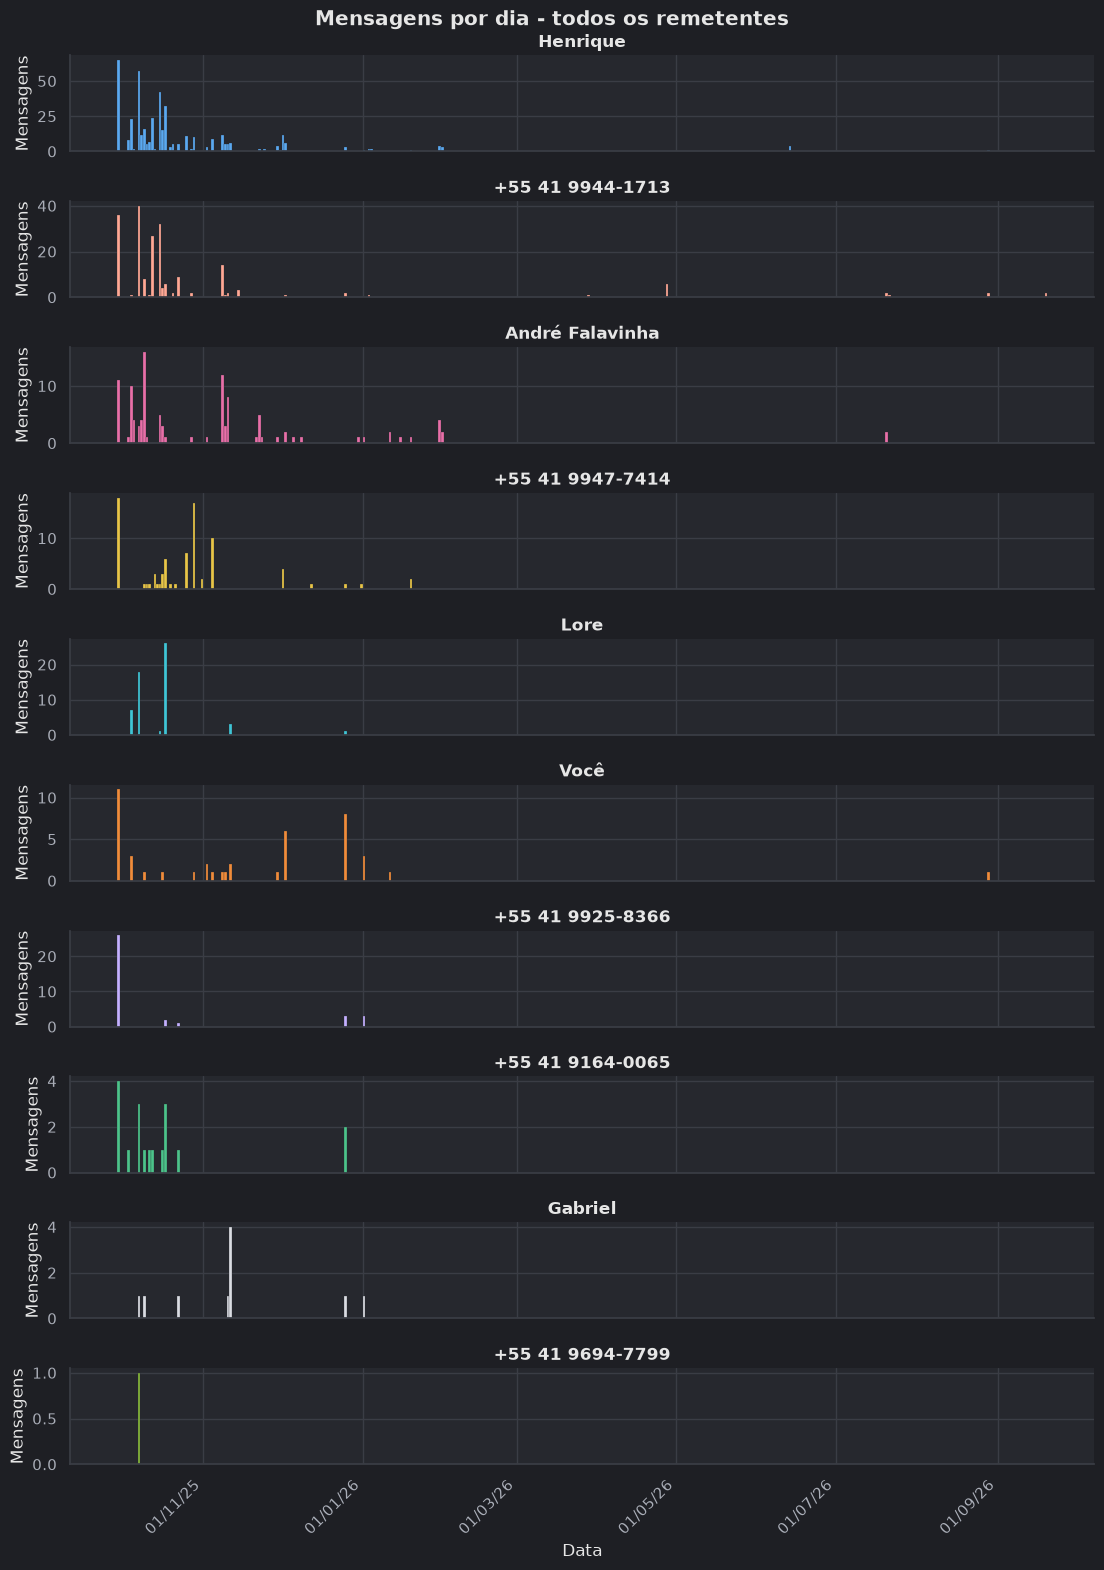

In [8]:
mostrar_figura(grafico_historico_remetente(df))

---

## 7. Gráfico

Percentual de mensagens de cada remetente. Fatias menores que 3 % não mostram o número dentro da fatia:

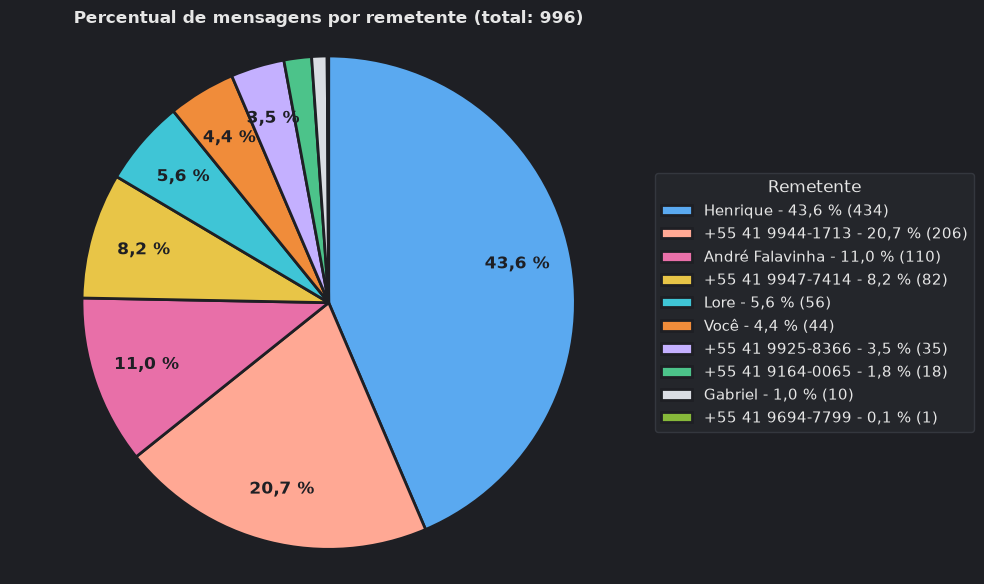

In [9]:
mostrar_figura(grafico_pizza(df))

---

## 8. Gráfico de linhas

Mensagens ao longo do tempo, todos os remetentes no mesmo gráfico, uma cor por remetente. Primeiro por **dia** e depois por **mês**, mais legível numa conversa longa. `freq` aceita `"D"` (dia), `"W"` (semana) e `"MS"` (mês).

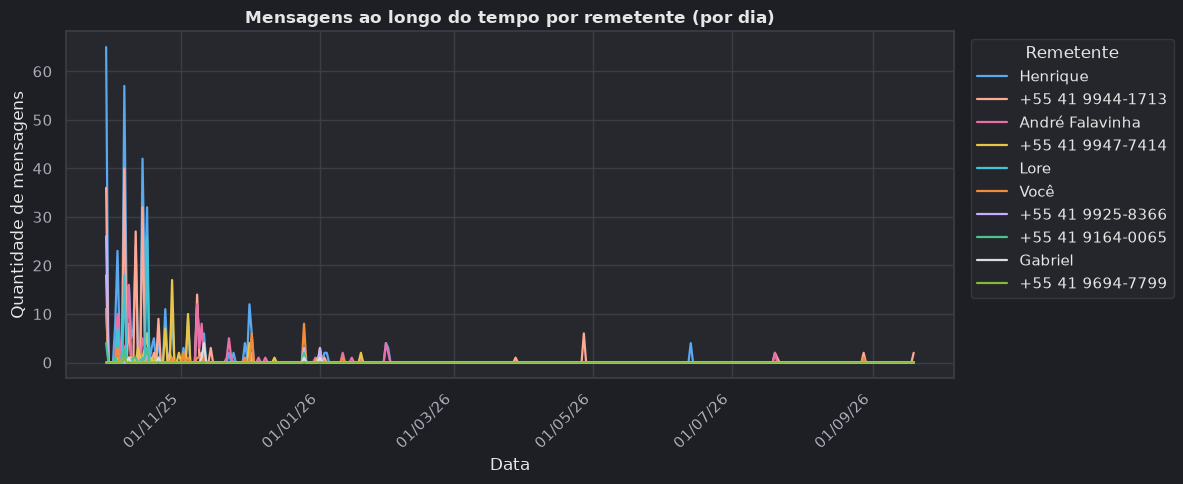

In [10]:
mostrar_figura(grafico_linhas(df, freq="D"))

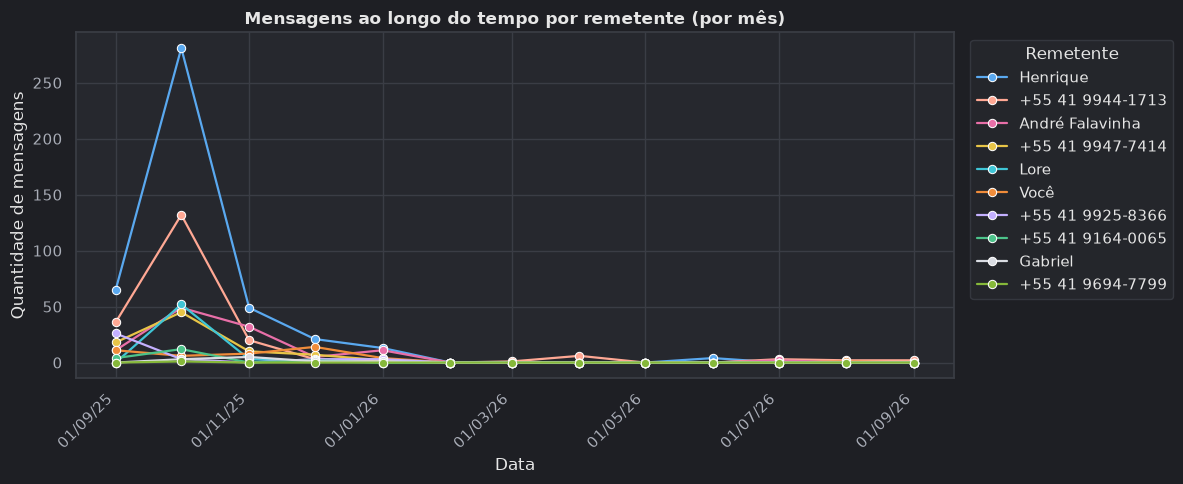

In [11]:
mostrar_figura(grafico_linhas(df, freq="MS"))

---

# Conclusões

Consideramos algo como uma aplicação web para o desenvolvimento do projeto, mas consideramos que um notebook estaria mais próximo do assunto das aulas anteriores 
e portanto escolhemos utilizar o jupyter lab ao invés de algo como FastAPI